# Lab 1 (part 2) — Data, models, training and saving in PyTorch

In `tensors.ipynb` we learned how to work with tensors and how autograd computes derivatives, and we ended
with gradient descent written by hand. Now we put all the pieces together and **train a real neural network**
to classify images of clothing.

Every deep learning project follows the same recipe, which is also the structure of this notebook:

1. **Data** → `Dataset` and `DataLoader`
2. **Model** → a class that inherits from `nn.Module`
3. **Loss and optimizer** → what to minimize and how to update the weights
4. **Training loop** → forward, loss, backward, step... repeated for several epochs
5. **Saving and loading** → so we don't lose the trained model

🔗 Throughout the notebook, references like *(→ tensors §13.7)* point to the section of the first notebook
where a concept was introduced.

**Contents**
1. Setup
2. Data: `Dataset` and `DataLoader`
3. Building the model with `nn.Module`
4. Training: loss, optimizer and the optimization loop
5. Saving and loading models
6. Exercises

## 1. Setup

In addition to `torch` we now need `torchvision`, the PyTorch library for computer vision (datasets,
image transforms, pretrained models).

In [1]:
# !pip install torch torchvision matplotlib

import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader, Dataset
from torchvision import datasets
from torchvision.transforms import Lambda, ToTensor

torch.manual_seed(0)

# Same device selection as in tensors §4.2
if torch.cuda.is_available():
    device = "cuda"
elif torch.backends.mps.is_available():
    device = "mps"
else:
    device = "cpu"
print(f"Using device: {device}")

Using device: cuda


---
## 2. Data: `Dataset` and `DataLoader`

PyTorch separates two responsibilities:
- a **`Dataset`** knows how many samples there are and how to fetch *one* sample (input + label);
- a **`DataLoader`** wraps a `Dataset` and serves it in **mini-batches**, optionally shuffled.

### 2.1 Loading a ready-made dataset: FashionMNIST

[FashionMNIST](https://github.com/zalandoresearch/fashion-mnist) contains 70,000 grayscale 28×28 images of
clothing items in 10 classes (60,000 for training, 10,000 for testing). `torchvision` downloads it for us
(~30 MB, only the first time).

The `transform=ToTensor()` argument converts each image from a PIL image with integer pixels in $[0, 255]$
to a `float32` tensor with values in $[0, 1]$ and shape $C \times H \times W$ (→ tensors §6, `permute`).

In [3]:
training_data = datasets.FashionMNIST(
    root="data",        # where to store the files
    train=True,         # training split
    download=True,
    transform=ToTensor(),
)

test_data = datasets.FashionMNIST(
    root="data",
    train=False,        # test split
    download=True,
    transform=ToTensor(),
)

print(f"Training samples: {len(training_data)}")
print(f"Test samples:     {len(test_data)}")

100%|██████████| 26.4M/26.4M [00:00<00:00, 116MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 3.73MB/s]
100%|██████████| 4.42M/4.42M [00:00<00:00, 62.5MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 13.5MB/s]


Training samples: 60000
Test samples:     10000


A `Dataset` is indexed like a list: `training_data[i]` returns the pair `(image, label)`.
Let's check shape, dtype and range of a sample (→ tensors §4: shape, dtype and device are the first things to check!).

In [4]:
img, label = training_data[0]
print(f"Image: shape={tuple(img.shape)}, dtype={img.dtype}, min={img.min():.2f}, max={img.max():.2f}")
print(f"Label: {label} ({type(label).__name__})")

Image: shape=(1, 28, 28), dtype=torch.float32, min=0.00, max=1.00
Label: 9 (int)


### 2.2 Visualizing the data

Always look at your data before training! To show an image with matplotlib we remove the channel
dimension of size 1 with `squeeze()` (→ tensors §6): $1 \times 28 \times 28 \rightarrow 28 \times 28$.

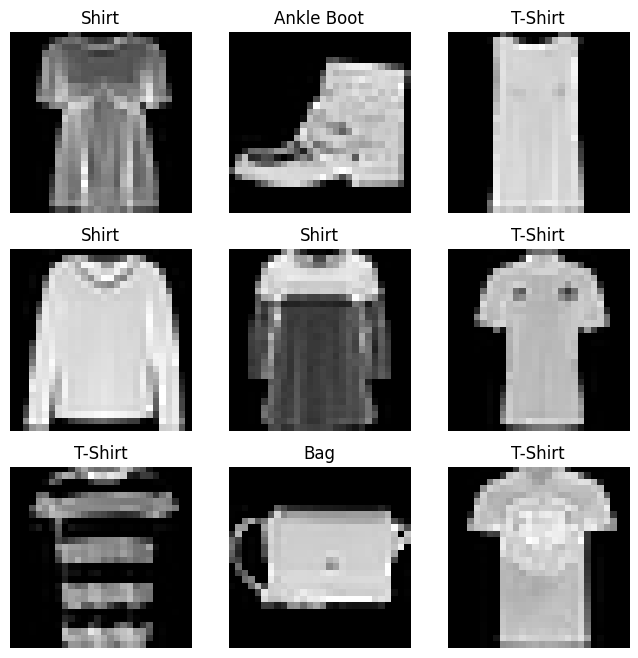

In [5]:
labels_map = {
    0: "T-Shirt", 1: "Trouser", 2: "Pullover", 3: "Dress", 4: "Coat",
    5: "Sandal", 6: "Shirt", 7: "Sneaker", 8: "Bag", 9: "Ankle Boot",
}

figure = plt.figure(figsize=(8, 8))
cols, rows = 3, 3
for i in range(1, cols * rows + 1):
    sample_idx = torch.randint(len(training_data), size=(1,)).item()
    img, label = training_data[sample_idx]
    figure.add_subplot(rows, cols, i)
    plt.title(labels_map[label])
    plt.axis("off")
    plt.imshow(img.squeeze(), cmap="gray")
plt.show()

### 2.3 Writing your own `Dataset`

For your own data you write a class that inherits from `Dataset` and implements **three methods**:

| Method | What it does |
|---|---|
| `__init__` | runs once: stores paths, reads the annotation file, sets up transforms |
| `__len__` | returns the number of samples |
| `__getitem__(idx)` | loads and returns **one** sample `(input, label)` given its index |

A typical example: images stored in a folder, with a CSV file listing `filename, label`.
(We only define the class here, since we don't have such a folder.)

In [6]:
import os

import pandas as pd
from torchvision.io import read_image


class CustomImageDataset(Dataset):
    def __init__(self, annotations_file, img_dir, transform=None, target_transform=None):
        self.img_labels = pd.read_csv(annotations_file)   # columns: filename, label
        self.img_dir = img_dir
        self.transform = transform
        self.target_transform = target_transform

    def __len__(self):
        return len(self.img_labels)

    def __getitem__(self, idx):
        img_path = os.path.join(self.img_dir, self.img_labels.iloc[idx, 0])
        image = read_image(img_path)                       # loaded only when requested
        label = self.img_labels.iloc[idx, 1]
        if self.transform:
            image = self.transform(image)
        if self.target_transform:
            label = self.target_transform(label)
        return image, label

💡 Note that images are read from disk **inside** `__getitem__`, not in `__init__`: this way the dataset does
not need to fit in memory, and only the images actually requested are loaded.

Here is a small dataset we can actually run: points $x \in [-3, 3]$ with a noisy target $y = \sin(x) + \varepsilon$.
Data can be generated or loaded however we like: PyTorch only cares about `__len__` and `__getitem__`.

Length: 200
Sample 0: (tensor([-3.]), tensor([-0.0974]))


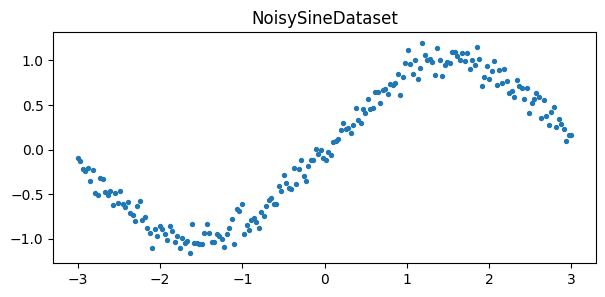

In [7]:
class NoisySineDataset(Dataset):
    def __init__(self, n_samples=200, noise=0.1):
        self.x = torch.linspace(-3, 3, n_samples).unsqueeze(1)          # shape (N, 1)
        self.y = torch.sin(self.x) + noise * torch.randn_like(self.x)   # shape (N, 1)

    def __len__(self):
        return len(self.x)

    def __getitem__(self, idx):
        return self.x[idx], self.y[idx]


sine_data = NoisySineDataset()
print(f"Length: {len(sine_data)}")
print(f"Sample 0: {sine_data[0]}")

plt.figure(figsize=(7, 3))
plt.scatter(sine_data.x, sine_data.y, s=8)
plt.title("NoisySineDataset")
plt.show()

### 2.4 Transforms on the labels

`transform` acts on the input, `target_transform` on the label. For example, we can turn the class index into a
**one-hot** vector using `Lambda` and the in-place `scatter_` operation (→ tensors §11):

In [8]:
one_hot = Lambda(lambda y: torch.zeros(10, dtype=torch.float).scatter_(0, torch.tensor(y), value=1))

ds_one_hot = datasets.FashionMNIST(root="data", train=True, download=True,
                                   transform=ToTensor(), target_transform=one_hot)
_, y = ds_one_hot[0]
print(f"Original label: {training_data[0][1]}  ->  one-hot: {y}")

Original label: 9  ->  one-hot: tensor([0., 0., 0., 0., 0., 0., 0., 0., 0., 1.])


We will **not** need this for training: as we will see in §4.2, `nn.CrossEntropyLoss` wants the class index directly.

### 2.5 `DataLoader`: mini-batches

During training we don't feed one sample at a time (too slow) nor the whole dataset at once (too much memory):
we use **mini-batches**. The `DataLoader` takes care of:
- grouping samples into batches (`batch_size`), stacking them into a single tensor (→ tensors §7, `stack`);
- **shuffling** the data at every epoch (`shuffle=True`), which is important for training;
- loading data in parallel (`num_workers`, not needed here).

In [9]:
batch_size = 64

train_dataloader = DataLoader(training_data, batch_size=batch_size, shuffle=True)
test_dataloader = DataLoader(test_data, batch_size=batch_size, shuffle=False)   # no need to shuffle the test set

print(f"Batches per epoch: {len(train_dataloader)}  (= ceil(60000 / {batch_size}))")

Batches per epoch: 938  (= ceil(60000 / 64))


A `DataLoader` is an *iterable*: we normally loop over it with `for X, y in dataloader`. To look at a single batch
we can use `next(iter(...))`. Note the new first dimension: the **batch dimension** (→ tensors §2, 4D tensors).

Feature batch shape: (64, 1, 28, 28)   (batch, channels, H, W)
Labels batch shape:  (64,), dtype=torch.int64


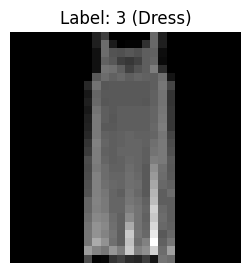

In [10]:
train_features, train_labels = next(iter(train_dataloader))
print(f"Feature batch shape: {tuple(train_features.shape)}   (batch, channels, H, W)")
print(f"Labels batch shape:  {tuple(train_labels.shape)}, dtype={train_labels.dtype}")

img = train_features[0].squeeze()
label = train_labels[0].item()
plt.figure(figsize=(3, 3))
plt.imshow(img, cmap="gray")
plt.title(f"Label: {label} ({labels_map[label]})")
plt.axis("off")
plt.show()

---
## 3. Building the model with `nn.Module`

The `torch.nn` module contains all the building blocks (*layers*) to build neural networks.
Before assembling the complete network, let's look at the layers one by one, following a batch of 3 fake images.

In [11]:
input_image = torch.rand(3, 28, 28)
print(input_image.shape)

torch.Size([3, 28, 28])


### 3.1 The layers one by one

**`nn.Flatten`** turns each $28 \times 28$ image into a vector of 784 values, keeping the batch dimension
(it is a `reshape`, → tensors §6).

In [12]:
flatten = nn.Flatten()
flat_image = flatten(input_image)
print(flat_image.shape)

torch.Size([3, 784])


**`nn.Linear`** applies $y = xW^T + b$ — exactly the linear layer we built by hand in tensors §13.9, but now PyTorch
creates and initializes the weights for us. Let's verify that it does nothing more than a matrix product plus bias:

In [13]:
layer1 = nn.Linear(in_features=28 * 28, out_features=20)
hidden1 = layer1(flat_image)
print("Output shape:", hidden1.shape)
print("Weight shape:", layer1.weight.shape, " Bias shape:", layer1.bias.shape)

manual = flat_image @ layer1.weight.T + layer1.bias       # broadcasting of the bias (→ tensors §9)
print("Same as x @ W.T + b?", torch.allclose(hidden1, manual))

Output shape: torch.Size([3, 20])
Weight shape: torch.Size([20, 784])  Bias shape: torch.Size([20])
Same as x @ W.T + b? True


**`nn.ReLU`** is the nonlinearity $\max(0, x)$ that we implemented with a boolean mask in tensors §5.1.
Without nonlinearities, a stack of linear layers would still be a single linear function!

In [14]:
print(f"Before ReLU: {hidden1[0, :6]}")
hidden1 = nn.ReLU()(hidden1)
print(f"After ReLU:  {hidden1[0, :6]}")

Before ReLU: tensor([-0.0152, -0.4352, -0.2168,  0.1221, -0.0089,  0.0600],
       grad_fn=<SliceBackward0>)
After ReLU:  tensor([0.0000, 0.0000, 0.0000, 0.1221, 0.0000, 0.0600],
       grad_fn=<SliceBackward0>)


**`nn.Sequential`** chains modules: the data flows through them in the given order.

In [15]:
seq_modules = nn.Sequential(
    flatten,
    layer1,
    nn.ReLU(),
    nn.Linear(20, 10),
)
logits = seq_modules(input_image)
print("Logits shape:", logits.shape)   # 3 images, 10 scores (one per class)

Logits shape: torch.Size([3, 10])


The last layer returns **logits**: raw, unbounded scores, one per class. **`nn.Softmax`** turns them into
probabilities (positive, summing to 1): $\text{softmax}(z)_i = \dfrac{e^{z_i}}{\sum_j e^{z_j}}$.
`dim=1` means "along the class dimension" (→ tensors §10).

In [16]:
softmax = nn.Softmax(dim=1)
pred_probab = softmax(logits)
print("Probabilities of the first image:", pred_probab[0])
print("Sum per image:", pred_probab.sum(dim=1))

Probabilities of the first image: tensor([0.1118, 0.1353, 0.1011, 0.1369, 0.0942, 0.0822, 0.1126, 0.0658, 0.0918,
        0.0683], grad_fn=<SelectBackward0>)
Sum per image: tensor([1.0000, 1.0000, 1.0000], grad_fn=<SumBackward1>)


### 3.2 Defining the network as a class

In practice we define a model as a class that inherits from **`nn.Module`**:
- in `__init__` we create the layers (and call `super().__init__()` first!);
- in `forward` we describe how the input flows through them.

We never call `forward` directly: we call `model(x)`, which runs `forward` plus some internal PyTorch machinery.

In [17]:
class NeuralNetwork(nn.Module):
    def __init__(self):
        super().__init__()
        self.flatten = nn.Flatten()
        self.linear_relu_stack = nn.Sequential(
            nn.Linear(28 * 28, 512), # l'output del primo layer è 512, 
            nn.ReLU(),
            nn.Linear(512, 512), # quindi il secondo layer deve avere come input 512
            nn.ReLU(),
            nn.Linear(512, 10),
        )

    def forward(self, x):
        x = self.flatten(x)
        logits = self.linear_relu_stack(x)
        return logits


model = NeuralNetwork().to(device)   # move all the parameters to the device (→ tensors §4.2)
print(model)

NeuralNetwork(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (linear_relu_stack): Sequential(
    (0): Linear(in_features=784, out_features=512, bias=True)
    (1): ReLU()
    (2): Linear(in_features=512, out_features=512, bias=True)
    (3): ReLU()
    (4): Linear(in_features=512, out_features=10, bias=True)
  )
)


### 3.3 Using the (untrained) model

We pass an input, get the logits, convert them to probabilities and take the most likely class with
`argmax` (→ tensors §10). The input must be on the **same device** as the model (→ tensors §4.2).
Since the weights are random, the prediction is meaningless for now.

In [18]:
X = torch.rand(1, 28, 28, device=device)
logits = model(X)
pred_probab = nn.Softmax(dim=1)(logits)
y_pred = pred_probab.argmax(1)
print(f"Predicted class: {y_pred.item()} ({labels_map[y_pred.item()]})")

Predicted class: 9 (Ankle Boot)


### 3.4 Model parameters

`nn.Module` automatically keeps track of all the weights and biases of its layers. They are tensors with
`requires_grad=True` (→ tensors §13): these are the tensors autograd will compute gradients for.

In [19]:
for name, param in model.named_parameters():
    print(f"{name:28s} shape={str(tuple(param.shape)):12s} requires_grad={param.requires_grad}")

n_params = sum(p.numel() for p in model.parameters())
print(f"\nTotal number of parameters: {n_params:,}")

linear_relu_stack.0.weight   shape=(512, 784)   requires_grad=True
linear_relu_stack.0.bias     shape=(512,)       requires_grad=True
linear_relu_stack.2.weight   shape=(512, 512)   requires_grad=True
linear_relu_stack.2.bias     shape=(512,)       requires_grad=True
linear_relu_stack.4.weight   shape=(10, 512)    requires_grad=True
linear_relu_stack.4.bias     shape=(10,)        requires_grad=True

Total number of parameters: 669,706


---
## 4. Training: loss, optimizer and the optimization loop

Training is the same gradient descent we wrote by hand in tensors §14, only with ~670k parameters instead of one,
and with the loss computed on mini-batches of data.

### 4.1 Hyperparameters

Hyperparameters are the values **we** choose (they are not learned):
- **epochs**: how many times we go through the whole dataset;
- **batch size**: how many samples per update (we set it to 64 in §2.5);
- **learning rate**: the step size $\eta$ (→ tensors §14: too small is slow, too large diverges).

In [20]:
learning_rate = 1e-2
epochs = 5

### 4.2 The loss function

For classification we use **`nn.CrossEntropyLoss`**. Two things to know:
- it takes the **logits** directly (it applies softmax internally, in a numerically stable way), so the model
  must **not** end with a softmax;
- the targets are **class indices** of type `int64` (→ tensors §4.1), not one-hot vectors.

It computes $-\log(p_{\text{correct class}})$ averaged over the batch: it is small when the model assigns high
probability to the right class.

In [21]:
loss_fn = nn.CrossEntropyLoss()

logits = torch.tensor([[4.0, 1.0, 0.1],     # confident and correct (class 0)
                       [0.1, 0.2, 3.0]])    # confident but wrong (true class 1)
targets = torch.tensor([0, 1])
print("Per-sample loss:", nn.CrossEntropyLoss(reduction="none")(logits, targets))

Per-sample loss: tensor([0.0677, 2.9096])


💡 Sanity check: an untrained model with 10 classes predicts roughly uniform probabilities, so the initial
loss should be close to $-\log(1/10) = \log(10) \approx 2.30$.

In [22]:
X, y = next(iter(train_dataloader))
with torch.no_grad():                      # no need for gradients here (→ tensors §13.8)
    initial_loss = loss_fn(model(X.to(device)), y.to(device))
print(f"Initial loss: {initial_loss.item():.3f}   log(10) = {torch.log(torch.tensor(10.)).item():.3f}")

Initial loss: 2.301   log(10) = 2.303


### 4.3 The optimizer

The optimizer implements the update rule. With **SGD**, `optimizer.step()` does exactly what we wrote by hand in
tensors §14, for every parameter: `p -= lr * p.grad`. And `optimizer.zero_grad()` resets the gradients, which
would otherwise **accumulate** (→ tensors §13.7).

| Manual (tensors §14) | With `torch.optim` |
|---|---|
| `with torch.no_grad(): x -= lr * x.grad` | `optimizer.step()` |
| `x.grad.zero_()` | `optimizer.zero_grad()` |

Let's verify it on a copy of one parameter:

In [23]:
optimizer = torch.optim.SGD(model.parameters(), lr=learning_rate)

X, y = next(iter(train_dataloader))
X, y = X.to(device), y.to(device)

optimizer.zero_grad()
loss_fn(model(X), y).backward()

w = model.linear_relu_stack[0].weight
expected = w.detach() - learning_rate * w.grad      # manual update
optimizer.step()                                    # update done by the optimizer
print("optimizer.step() == p - lr * p.grad ?", torch.allclose(w.detach(), expected))

optimizer.step() == p - lr * p.grad ? True


Other optimizers (e.g. `torch.optim.Adam`) use more sophisticated update rules, but the interface is identical:
you only change one line.

### 4.4 The training and test loops

One **epoch** has two phases:
- **train loop**: for each batch → forward → loss → `zero_grad` → `backward` → `step`;
- **test loop**: evaluate the model on data it has never seen, **without** updating the weights and without
  building the graph (`torch.no_grad()`, → tensors §13.8).

`model.train()` and `model.eval()` switch the behaviour of layers such as Dropout and BatchNorm. Our network has
none of them, but calling them is a good habit.

In [24]:
def train_loop(dataloader, model, loss_fn, optimizer):
    size = len(dataloader.dataset)
    model.train()
    total_loss = 0.0
    for batch, (X, y) in enumerate(dataloader):
        X, y = X.to(device), y.to(device)

        # 1. Forward: prediction and loss
        pred = model(X)
        loss = loss_fn(pred, y)

        # 2. Backpropagation
        optimizer.zero_grad()   # reset the gradients (→ tensors §13.7)
        loss.backward()         # compute dloss/dparam for every parameter (→ tensors §13)
        optimizer.step()        # update the parameters (→ tensors §14)

        total_loss += loss.item()   # .item() to get a Python number (→ tensors §10)
        if batch % 200 == 0:
            current = batch * len(X)
            print(f"  loss: {loss.item():>7f}  [{current:>5d}/{size:>5d}]")
    return total_loss / len(dataloader)


def test_loop(dataloader, model, loss_fn):
    size = len(dataloader.dataset)
    num_batches = len(dataloader)
    model.eval()
    test_loss, correct = 0.0, 0

    with torch.no_grad():
        for X, y in dataloader:
            X, y = X.to(device), y.to(device)
            pred = model(X)
            test_loss += loss_fn(pred, y).item()
            correct += (pred.argmax(1) == y).type(torch.float).sum().item()

    test_loss /= num_batches
    accuracy = correct / size
    print(f"  Test: accuracy {100 * accuracy:>0.1f}%, avg loss {test_loss:>8f}")
    return test_loss, accuracy

### 4.5 Training!

We re-create model and optimizer to start from scratch, then run the epochs. On a CPU each epoch takes a few seconds.

In [25]:
torch.manual_seed(0)
model = NeuralNetwork().to(device)
optimizer = torch.optim.SGD(model.parameters(), lr=learning_rate)

history = {"train_loss": [], "test_loss": [], "test_acc": []}
for t in range(epochs):
    print(f"Epoch {t + 1}\n-------------------------------")
    train_loss = train_loop(train_dataloader, model, loss_fn, optimizer)
    test_loss, test_acc = test_loop(test_dataloader, model, loss_fn)
    history["train_loss"].append(train_loss)
    history["test_loss"].append(test_loss)
    history["test_acc"].append(test_acc)
print("Done!")

Epoch 1
-------------------------------
  loss: 2.300577  [    0/60000]
  loss: 1.792235  [12800/60000]
  loss: 1.147786  [25600/60000]
  loss: 0.831217  [38400/60000]
  loss: 1.005314  [51200/60000]
  Test: accuracy 69.7%, avg loss 0.793515
Epoch 2
-------------------------------
  loss: 0.832114  [    0/60000]
  loss: 0.711992  [12800/60000]
  loss: 0.806025  [25600/60000]
  loss: 0.686899  [38400/60000]
  loss: 0.705438  [51200/60000]
  Test: accuracy 76.8%, avg loss 0.652582
Epoch 3
-------------------------------
  loss: 0.582984  [    0/60000]
  loss: 0.647746  [12800/60000]
  loss: 0.653431  [25600/60000]
  loss: 0.529913  [38400/60000]
  loss: 0.519060  [51200/60000]
  Test: accuracy 80.7%, avg loss 0.551321
Epoch 4
-------------------------------
  loss: 0.618613  [    0/60000]
  loss: 0.436368  [12800/60000]
  loss: 0.425066  [25600/60000]
  loss: 0.429082  [38400/60000]
  loss: 0.363402  [51200/60000]
  Test: accuracy 81.6%, avg loss 0.521739
Epoch 5
------------------------

### 4.6 Learning curves

Plotting loss and accuracy over the epochs is the first diagnostic tool: the loss should go down. If the training
loss keeps decreasing while the test loss goes up, the model is **overfitting**.

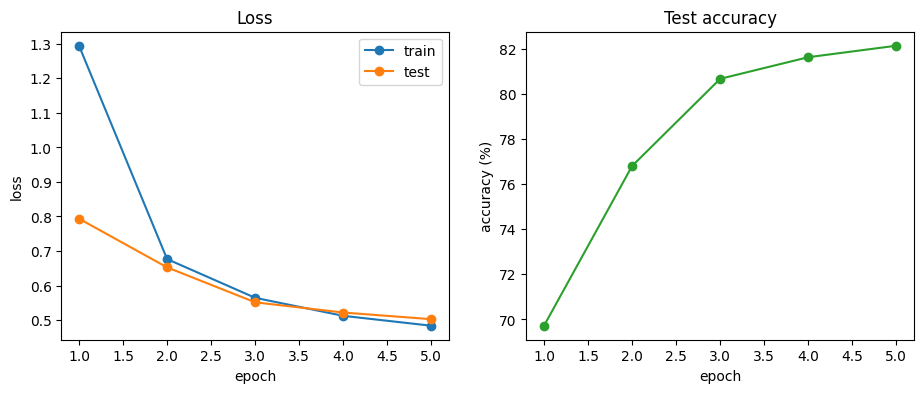

In [26]:
ep = range(1, epochs + 1)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
ax1.plot(ep, history["train_loss"], "o-", label="train")
ax1.plot(ep, history["test_loss"], "o-", label="test")
ax1.set_xlabel("epoch")
ax1.set_ylabel("loss")
ax1.legend()
ax1.set_title("Loss")
ax2.plot(ep, [100 * a for a in history["test_acc"]], "o-", color="tab:green")
ax2.set_xlabel("epoch")
ax2.set_ylabel("accuracy (%)")
ax2.set_title("Test accuracy")
plt.show()

### 4.7 Looking at the predictions

Numbers are good, but it is also worth looking at what the model gets right and wrong
(green = correct, red = wrong).

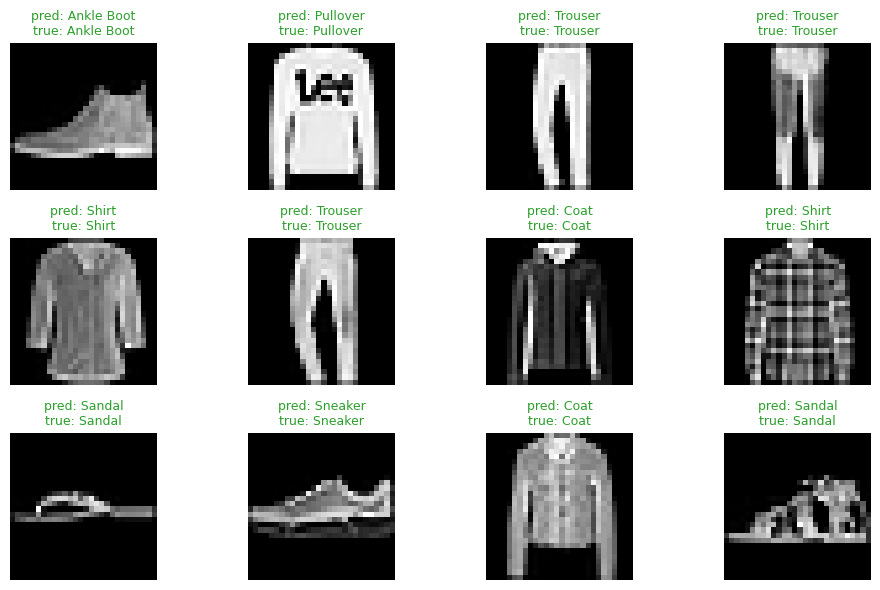

In [27]:
model.eval()
X, y = next(iter(test_dataloader))
with torch.no_grad():
    preds = model(X.to(device)).argmax(1).cpu()   # back to CPU for matplotlib

figure = plt.figure(figsize=(10, 6))
for i in range(12):
    ax = figure.add_subplot(3, 4, i + 1)
    ax.imshow(X[i].squeeze(), cmap="gray")
    color = "tab:green" if preds[i] == y[i] else "tab:red"
    ax.set_title(f"pred: {labels_map[preds[i].item()]}\ntrue: {labels_map[y[i].item()]}", color=color, fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

---
## 5. Saving and loading models

Training can take hours or days: we need to save the result.

### 5.1 The `state_dict`

All the learned parameters of a model are collected in its **`state_dict`**: a dictionary that maps each
parameter name to its tensor.

In [28]:
state = model.state_dict()
for name, tensor in state.items():
    print(f"{name:28s} {tuple(tensor.shape)}")

linear_relu_stack.0.weight   (512, 784)
linear_relu_stack.0.bias     (512,)
linear_relu_stack.2.weight   (512, 512)
linear_relu_stack.2.bias     (512,)
linear_relu_stack.4.weight   (10, 512)
linear_relu_stack.4.bias     (10,)


### 5.2 Saving and loading the weights (recommended way)

We save only the `state_dict` with `torch.save`. To load it, we first create a model with the **same architecture**,
then copy the weights into it with `load_state_dict`.

In [29]:
torch.save(model.state_dict(), "model_weights.pth")

model2 = NeuralNetwork().to(device)                  # fresh model with random weights
model2.load_state_dict(torch.load("model_weights.pth", weights_only=True))
model2.eval()                                        # remember: eval mode before inference!

with torch.no_grad():
    same = torch.equal(model(X.to(device)), model2(X.to(device)))
print("Loaded model gives the same outputs?", same)

Loaded model gives the same outputs? True


### 5.3 Saving the whole model

We can also save the entire model object (architecture + weights). It looks more convenient, but it relies on
Python's `pickle`: to load it, the class `NeuralNetwork` must be defined, and the file can break if the code changes.
Moreover, since PyTorch 2.6 `torch.load` refuses by default to load arbitrary Python objects for security reasons,
so we must pass `weights_only=False` explicitly (only do it for files you trust!).

👉 In practice: **prefer saving the `state_dict`**.

In [30]:
torch.save(model, "model.pth")
model3 = torch.load("model.pth", weights_only=False)
print(type(model3))

<class '__main__.NeuralNetwork'>


### 5.4 Checkpoints: resuming training

To *resume* an interrupted training, the weights are not enough: we also need the optimizer state (e.g. Adam
keeps running statistics for each parameter) and the epoch we reached. We save everything in a dictionary.

In [31]:
checkpoint = {
    "epoch": epochs,
    "model_state_dict": model.state_dict(),
    "optimizer_state_dict": optimizer.state_dict(),
    "history": history,
}
torch.save(checkpoint, "checkpoint.pth")

# ... later, or in another script:
checkpoint = torch.load("checkpoint.pth", weights_only=True)
model = NeuralNetwork().to(device)
optimizer = torch.optim.SGD(model.parameters(), lr=learning_rate)
model.load_state_dict(checkpoint["model_state_dict"])
optimizer.load_state_dict(checkpoint["optimizer_state_dict"])
start_epoch = checkpoint["epoch"]
print(f"Resuming from epoch {start_epoch}, last test accuracy {100 * checkpoint['history']['test_acc'][-1]:.1f}%")

# Train for one more epoch starting from where we left off
print(f"Epoch {start_epoch + 1}\n-------------------------------")
train_loop(train_dataloader, model, loss_fn, optimizer)
test_loop(test_dataloader, model, loss_fn)

Resuming from epoch 5, last test accuracy 82.2%
Epoch 6
-------------------------------
  loss: 0.465825  [    0/60000]
  loss: 0.418508  [12800/60000]
  loss: 0.547027  [25600/60000]
  loss: 0.554155  [38400/60000]
  loss: 0.408572  [51200/60000]
  Test: accuracy 82.0%, avg loss 0.509965


(0.5099650985875707, 0.8195)

### 5.5 Pretrained models from `torchvision` (optional)

`torchvision.models` provides famous architectures (ResNet, VGG, ...) with weights already trained on ImageNet.
They are loaded exactly as above: the architecture is created and a `state_dict` is loaded into it (downloaded
automatically the first time). We will use them later in the course for **transfer learning**.

⚠️ This downloads ~45 MB for ResNet-18 (VGG-16, used in the old version of this lab, is ~530 MB).

In [ ]:
import torchvision.models as models

resnet = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
resnet.eval()
print(f"ResNet-18 parameters: {sum(p.numel() for p in resnet.parameters()):,}")
print(f"Final layer: {resnet.fc}")   # 512 features -> 1000 ImageNet classes

Let's clean up the files we created.

In [32]:
for f in ["model_weights.pth", "model.pth", "checkpoint.pth"]:
    if os.path.exists(f):
        os.remove(f)

---
## 6. Exercises

1. **Optimizer.** Replace SGD with `torch.optim.Adam(model.parameters(), lr=1e-3)` and train for 5 epochs.
   Compare the learning curves with those of §4.6.
2. **Learning rate.** Train with SGD using `lr = 1e-3`, `1e-2` and `1e-1`. Which one works best in 5 epochs? Does
   this match what we saw in tensors §14?
3. **Architecture.** Modify `NeuralNetwork`: add a layer, change the width (e.g. 128 or 1024 neurons), or add
   `nn.Dropout(0.2)` after each ReLU. How do the number of parameters and the accuracy change?
4. **Regression.** Using `NoisySineDataset` (§2.3), a `DataLoader` and a small network
   (`nn.Linear(1, 32) → nn.ReLU() → nn.Linear(32, 1)`), learn to fit $\sin(x)$. Use `nn.MSELoss()` as the loss and
   plot the prediction on top of the data at the end.
5. **Per-class accuracy.** Compute the test accuracy separately for each of the 10 classes. Which classes are the
   hardest? Does it make sense looking at the images?